# GR05 · Task 4 — From engine readings to a modeling dataset
## A guided notebook for understanding **and** preparing the data
**Selçuk Ata Aksoy · Denzel Gregory Pragassa · HFU · WS 2026/27**  
29 October 2026 · CRISP-DM: Data Preparation

We already explored the raw files in Task 3. Now we decide **what one prediction means**, summarize the right information, handle missing values, split engines, and save an identifiable, reproducible version.

This is a preprocessing notebook, not a trained RUL model. No accuracy scores or business savings are claimed. Read the explanations and use the small worked examples to explain the project to someone new to analytics.

## 1 · Start with an everyday explanation
Imagine each engine has a diary:
- **One sensor reading** is a detailed snapshot taken during a flight: altitude, speed, temperature, pressure, fuel flow, and shaft speeds.
- **One flight** is a diary entry containing many snapshots. Hundreds or thousands of snapshots do not mean hundreds or thousands of separate engines.
- **One engine history** is the ordered collection of its flight entries.
- **RUL** is the answer written onto a historical entry: how many more flight cycles happened before that simulated engine reached its end-of-life.

For this version we predict **at the end of a completed flight**. We can use readings from that flight and earlier flights, but not later flights or the known future failure date. Our prepared row represents **one completed flight**. That decision makes the meaning of every feature explicit.

**Example, not a measured model output:** if an engine's historical final cycle was 100, flight 30 has RUL 70. A future prediction model must estimate that 70 from measurements; it must not be given the known final cycle 100.

### Which entries are relevant, and what do their numbers mean?
| Entry type | Examples | Why useful / what we do |
|---|---|---|
| Operating context | altitude, Mach, throttle, inlet temperature | Explain how hard/where the engine is operating; sensor changes can reflect flight conditions |
| Measured sensor channels | temperatures, pressures, fan/core rpm, fuel flow | Candidate evidence of engine response, combined with operating context |
| Grouping metadata | unit ID, cycle, source partition | Keep histories together, order flights, and stop leakage; not numeric predictors |
| Flight class | short/medium/long mission code | Kept for interpreting coverage, excluded from this baseline's predictors |
| Collection identity | DS01 or DS02 | One-hot categorical source indicator when integrating both collections |
| Target | historical RUL | Stored separately as y; never included in X |
| Hidden simulator information | health modifiers T, virtual X_v, health state hs | Excluded: not assumed available from physical sensors at prediction time |
| Unresolved physical channel | P2 | Excluded until its definition/unit is confirmed |

“Measured sensor” is a channel type in a simulator. The degradation and readings here are simulated, driven by realistic operating profiles, rather than observed actual engine failures.

Numbers are not all quantities: engine ID 10 is a label, not twice engine ID 5. Flight class 3 is not three times class 1. Temperatures are converted from absolute Rankine to Kelvin, not interpreted as Celsius.

## 2 · Setup and the exact task
From the repository root, activate `.venv`, install `requirements.txt`, then start Jupyter:
```bash
source .venv/bin/activate
python -m pip install -r requirements.txt
python -m jupyterlab
```
Select the project Python interpreter. Both original HDF5 files must be under `data/raw/`.

The supplied **Project Tasks V4.0 PDF**, p. 2, dated 26 October 2026, asks for cleaning, transformation/normalization, feature engineering, dataset integration, and versioned raw/processed storage. Its internal header still says V12.0. We use the supplied filename and page/date to identify it.

The first full run reads both raw files in chunks and computes hashes. Later runs reuse the matching prepared version **only after verifying its files**. If raw bytes, preprocessing code, configuration, or relevant package versions change, a new version directory is created. Raw files are read-only; the existing Task 3 notebook is not re-executed or overwritten.

In [1]:
from pathlib import Path
import sys, json
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/preprocessing.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open within the GR05 repository.')
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from IPython.display import display
from src.preprocessing import (prepare_data, verify_version, CHANNELS, META, NUMERIC_BASE,
                               feature_catalog, make_preprocessor)
pd.set_option('display.max_rows',60)
plt.rcParams.update({'figure.figsize':(11,4.6), 'figure.dpi':110,
                     'axes.spines.top':False,'axes.spines.right':False,
                     'axes.prop_cycle':plt.cycler(color=['#386757','#c3441f','#b38b48','#617f98'])})
config=json.loads((ROOT/'config/preprocessing.json').read_text())
display(pd.Series(config, name='chosen policy').to_frame())

,chosen policy
schema_version,task4-v1
files,"[N-CMAPSS_DS01-005.h5, N-CMAPSS_DS02-006.h5]"
prediction_point,end_of_completed_flight
chunk_rows,100000
validation_unit_ids,"[5, 6, 18]"
cross_dataset_grouping,conservatively_link_equal_unit_ids
exclude_unconfirmed_sensor,P2
rolling_window_flights,3
numeric_imputation,training_median_with_missing_indicators
scaling,training_standard_score_ddof_0


## 3 · Make the preparation choices before fitting anything
**Inputs:** 17 physical channels: the 4 operating conditions and 13 of the 14 measured sensor channels. `P2` is deliberately excluded while its source definition is unresolved.

**No automatic outlier deletion.** A rare flight condition is not necessarily a wrong measurement. Task 3's IQR flags were prompts to investigate, not permission to erase valid flights.

**Missing/inconsistent data policy:**
1. Read finite numeric sensor values; turn NaN/infinity and unambiguously impossible negative/zero absolute measurements into missing values. No guessed readings are inserted into the raw data.
2. Summarize the remaining finite readings for each flight; retain the number of original readings.
3. Refuse invalid engine/cycle/class/target values or inconsistent labels, rather than guessing an ID or target. Check flight order, label constancy, and the retrospective RUL relationship for auditing only.
4. Fill missing prepared features with **training medians**, then retain missingness indicators. Missing labels are never filled.

In these actual local files, the run will report how many invalid numbers it encountered; we do not invent a cleaning problem just to demonstrate cleaning. Previous-flight differences naturally have missing values at the start of each history.

### Transform units before scaling
| Raw | Physical representation used here |
|---|---|
| Altitude in ft | metres: ft × 0.3048 |
| Absolute temperature in °R | Kelvin: °R × 5/9 |
| Absolute pressure in psia | kPa: psia × 6.894757293168 |
| Fuel flow in lb/s | kg/s: lb/s × 0.45359237 |
| Mach, throttle %, rpm | retain their declared units |

Unit conversion changes the representation without learning from the data. Standardization later changes the numerical scale for algorithms; it does not remove operating-condition effects or isolate degradation.

In [2]:
units=pd.DataFrame([{'raw_channel':k,'prepared_stem':v[0],'physical_unit':v[1],'factor':v[2]}
                    for k,v in CHANNELS.items()])
display(units)
print('Worked unit example, not a measurement: 540 °R =', 540*5/9, 'K')

,raw_channel,prepared_stem,physical_unit,factor
0,alt,alt_m,m,0.304800
1,Mach,Mach,dimensionless,1.000000
2,TRA,TRA_pct,%,1.000000
3,T2,T2_K,K,0.555556
4,T24,T24_K,K,0.555556
5,T30,T30_K,K,0.555556
6,T48,T48_K,K,0.555556
7,T50,T50_K,K,0.555556
8,P15,P15_kPa,kPa,6.894757
9,P21,P21_kPa,kPa,6.894757


Worked unit example, not a measurement: 540 °R = 300.0 K


## 4 · Integrate DS01 and DS02 without pretending the histories are independent
Both files use a compatible schema, so we can append their prepared flight rows into one table. We preserve dataset identity (`DS01:2` differs from `DS02:2` as a source history).

However, equal IDs and lifetimes occur across subsets. We have not established whether they describe independent engines. Therefore **equal raw unit IDs are conservatively linked for splitting**, without claiming that they are the same physical engine.

A critical case: DS01 unit 10 is supplied **test**, whereas DS02 unit 10 is supplied **development**. Its DS02 development flights are saved in a quarantine table and used in neither training nor validation. This prevents that known cross-subset risk without relabeling supplied test data.

Predeclared validation IDs are **5, 6, 18**. Remaining eligible development histories are training; all supplied test histories remain test. The choice is fixed for this version and has not been selected using model performance. Validation is small; later cross-validation must respect the same conservative groups and re-fit preprocessing inside every training fold.

## 5 · Execute the complete preprocessing pipeline
This calls `src/preprocessing.py`. All full-resolution raw processing is in bounded chunks; only small flight tables stay in memory. The output is a local version under `data/processed/` (ignored by Git).

In [3]:
version_dir, manifest = prepare_data(ROOT)
assert verify_version(version_dir)['version_id'] == manifest['version_id']
features=pd.read_csv(version_dir/'flights_features.csv')
catalog=pd.read_csv(version_dir/'feature_catalog.csv')
cleaning=pd.read_csv(version_dir/'cleaning_audit.csv')
split_summary=pd.read_csv(version_dir/'split_summary.csv')
engine_splits=pd.read_csv(version_dir/'engine_splits.csv')
imputation=pd.read_csv(version_dir/'imputation_parameters.csv')
scaling=pd.read_csv(version_dir/'scaling_parameters.csv')
print('Version:',manifest['version_id'])
print('Local directory:',version_dir.relative_to(ROOT))
display(cleaning)
display(split_summary)
display(engine_splits)

DS01/dev: 4,906,636 readings → 553 completed flights


DS01/test: 2,735,232 readings → 341 completed flights


DS02/dev: 5,263,447 readings → 446 completed flights


DS02/test: 1,253,743 readings → 202 completed flights


Created immutable prepared version: task4-v1-97719f3fe055


Version: task4-v1-97719f3fe055
Local directory: data/processed/task4-v1-97719f3fe055


,dataset,partition,raw_readings,predictor_nonfinite,impossible_predictor_values,readings_removed,invalid_key_or_label_rows
0,DS01,dev,4906636,0,0,0,0
1,DS01,test,2735232,0,0,0,0
2,DS02,dev,5263447,0,0,0,0
3,DS02,test,1253743,0,0,0,0


,dataset,source_partition,split,flights,histories,raw_readings
0,DS01,dev,train,370,4,2789639
1,DS01,dev,validation,183,2,2116997
2,DS01,test,test,341,4,2735232
3,DS02,dev,quarantine_test_related,82,1,952711
4,DS02,dev,train,204,3,2386597
5,DS02,dev,validation,160,2,1924139
6,DS02,test,test,202,3,1253743


,dataset,source_partition,unit,engine_id,conservative_group,flight_class,split
0,DS01,dev,1,DS01:1,unit:1,1,train
1,DS01,dev,2,DS01:2,unit:2,3,train
2,DS01,dev,3,DS01:3,unit:3,2,train
3,DS01,dev,4,DS01:4,unit:4,1,train
4,DS01,dev,5,DS01:5,unit:5,3,validation
5,DS01,dev,6,DS01:6,unit:6,2,validation
6,DS01,test,7,DS01:7,unit:7,1,test
7,DS01,test,8,DS01:8,unit:8,2,test
8,DS01,test,9,DS01:9,unit:9,1,test
9,DS01,test,10,DS01:10,unit:10,3,test


### What “cleaned” means in our actual result
The audit above reports exact counts, including zero when there was nothing to remove. Cleaned does not mean “we deleted suspicious-looking data.” It means our chosen schema and consistency checks were enforced, known unavailable fields excluded, units made explicit, valid readings summarized, and missing prepared values handled.

The 82 quarantined flights are retained in the version. They are excluded from training/validation because of possible related test history, not because their sensor values were bad. Raw data and full integrated features remain available locally.

In [4]:
comparison=pd.DataFrame([
    {'stage':'raw readings','rows':manifest['raw_readings'],'columns_or_role':'47 stored fields across six blocks'},
    {'stage':'integrated flight table','rows':manifest['processed_flights'],'columns_or_role':'45 numeric candidates + metadata + RUL'},
    *[{'stage':split+' model matrix','rows':shape[0],'columns_or_role':str(shape[1])+' finite model columns'}
      for split,shape in manifest['matrix_shapes'].items()],
    {'stage':'quarantined flights','rows':manifest['quarantined_flights'],'columns_or_role':'retained locally; no fitting or evaluation'}])
display(comparison)
print('Raw invalid/non-finite predictor cells:',manifest['predictor_nonfinite'])
print('Physically impossible predictor cells:',manifest['impossible_predictor_values'])
print('Raw readings deleted:',manifest['readings_removed'])
comparison.to_csv(ROOT/'reports/results/task4/raw_processed_comparison.csv', index=False)

,stage,rows,columns_or_role
0,raw readings,14159058,47 stored fields across six blocks
1,integrated flight table,1542,45 numeric candidates + metadata + RUL
2,train model matrix,574,50 finite model columns
3,validation model matrix,343,50 finite model columns
4,test model matrix,543,50 finite model columns
5,quarantined flights,82,retained locally; no fitting or evaluation


Raw invalid/non-finite predictor cells: 0
Physically impossible predictor cells: 0
Raw readings deleted: 0


## 6 · Feature engineering — what information are we giving a future model?
We create **45 numeric candidate features**:
- **17 current-flight means**: typical level of each channel during this flight.
- **17 current-flight standard deviations**: how much each signal varied inside this flight. Sample standard deviation uses ddof 1.
- **1 reading count**: number of recorded snapshots; a flight-length proxy, not independently verified seconds.
- **3 trailing averages**: current and up to two earlier flight means for T48, core speed, and fuel flow.
- **3 previous-flight differences** for those channels: current mean minus previous mean.
- **4 physical combinations**: two pressure ratios, a temperature difference, and core/fan speed ratio, all calculated from current-flight means.

The catalog below documents every formula, unit, source, and availability. Ratios are **ratios of flight means**, not means of instantaneous ratios. They are candidate descriptors, not validated wear or efficiency estimates.

A smaller **20-column baseline selection** is also saved: 17 means + reading count + 2 source indicators. This keeps the semester project manageable. Engineered candidates should only be retained later if development-engine validation supports them.

In [5]:
display(catalog)
print('Families:')
display(catalog.groupby('family').size().rename('feature_count').to_frame())
example=features[(features.dataset=='DS01')&(features.unit==1)].head(5)
display(example[['dataset','unit','cycle','RUL','T48_K_mean','T48_K_std','T48_K_trailing3','T48_K_delta_prev']])
# This calculation looks backward only; no centered window, backward fill,
# final-lifetime normalization, or future RUL is used as a feature.
assert pd.isna(example.iloc[0].T48_K_delta_prev)
assert np.isclose(example.iloc[2].T48_K_trailing3,example.iloc[:3].T48_K_mean.mean())

,feature,family,source,unit,definition,conversion_factor,available,baseline
0,alt_m_mean,current_flight,alt,m,Mean of finite readings in the current complet...,0.304800,end of current flight,True
1,alt_m_std,current_flight,alt,m,Sample standard deviation of finite readings i...,0.304800,end of current flight,False
2,Mach_mean,current_flight,Mach,dimensionless,Mean of finite readings in the current complet...,1.000000,end of current flight,True
3,Mach_std,current_flight,Mach,dimensionless,Sample standard deviation of finite readings i...,1.000000,end of current flight,False
4,TRA_pct_mean,current_flight,TRA,%,Mean of finite readings in the current complet...,1.000000,end of current flight,True
5,TRA_pct_std,current_flight,TRA,%,Sample standard deviation of finite readings i...,1.000000,end of current flight,False
6,T2_K_mean,current_flight,T2,K,Mean of finite readings in the current complet...,0.555556,end of current flight,True
7,T2_K_std,current_flight,T2,K,Sample standard deviation of finite readings i...,0.555556,end of current flight,False
8,T24_K_mean,current_flight,T24,K,Mean of finite readings in the current complet...,0.555556,end of current flight,True
9,T24_K_std,current_flight,T24,K,Sample standard deviation of finite readings i...,0.555556,end of current flight,False


Families:


,feature_count
family,
causal_history,6
current_flight,35
physical_combination,4


,dataset,unit,cycle,RUL,T48_K_mean,T48_K_std,T48_K_trailing3,T48_K_delta_prev
0,DS01,1,1,99,916.717842,69.482574,916.717842,NaN
1,DS01,1,2,98,904.209021,69.339257,910.463432,-12.508820
2,DS01,1,3,97,904.710659,61.110113,908.545841,0.501638
3,DS01,1,4,96,904.490170,85.761965,904.469950,-0.220489
4,DS01,1,5,95,902.314701,77.561770,903.838510,-2.175469


## 7 · Missing values, encoding, and scaling — in ordinary language
**Imputation:** when a prepared feature is missing, fill it using the middle value (median) from training flights. The first flight has no earlier flight, so its “change since previous flight” is genuinely unknown. An extra indicator records that absence. This is not a missing target.

**Encoding:** the collection label DS01/DS02 becomes two separate 0/1 columns. We do not encode engine IDs as predictors, and `Fc` remains diagnostic metadata.

**Scaling:** each imputed numeric feature (including its missingness indicators) is centered and divided by the training standard deviation (population ddof 0). A scaled value of 1 means one training standard deviation above the training mean, not “one cycle of remaining life.” Constant training columns use scale 1. Source indicator columns remain unscaled 0/1.

**The crucial rule:** fit imputer and scaler on training flights only; use `transform` on validation/test. Validation/test means do not need to be zero and their values are not clipped into a training range. A shift outside training can be meaningful.

In [6]:
pipeline=joblib.load(version_dir/'preprocessor.joblib')
# Loading is from the locally created, hash-verified artifact.
display(pipeline)
display(imputation[imputation.missing_all>0])
display(scaling.head(12))
print('Missing numeric cells before imputation:',manifest['missing_numeric_features'])
print('Missingness indicators:',manifest['learned_missing_indicators'])
print('Maximum absolute numeric TRAIN column mean after scaling:',manifest['fit_numeric_max_abs_mean'])

X_train=pd.read_csv(version_dir/'X_train.csv')
X_validation=pd.read_csv(version_dir/'X_validation.csv')
X_test=pd.read_csv(version_dir/'X_test.csv')
y_train=pd.read_csv(version_dir/'y_train.csv')['RUL']
for split in ['train','validation','test']:
    X=pd.read_csv(version_dir/f'X_{split}.csv')
    y=pd.read_csv(version_dir/f'y_{split}.csv')
    rows=pd.read_csv(version_dir/f'rows_{split}.csv')
    assert len(X)==len(y)==len(rows)
    assert np.isfinite(X.to_numpy()).all()
    assert len(X.columns)==manifest['model_columns']
print('All model matrices finite; row metadata and targets align.')
display(X_train.head(3))
baseline_columns=json.loads((version_dir/'baseline_columns.json').read_text())
X_train_baseline=X_train[baseline_columns]
print('Smaller baseline matrix:',X_train_baseline.shape)

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('source', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature

,feature,training_median,missing_train,missing_all
36,T48_K_delta_prev,0.362617,7,19
38,Nc_rpm_delta_prev,-0.066453,7,19
40,Wf_kg_s_delta_prev,0.000625,7,19


,output_feature,training_mean,training_scale
0,numeric__alt_m_mean,4739.440690,1782.910414
1,numeric__alt_m_std,1525.950114,577.303192
2,numeric__Mach_mean,0.538981,0.079675
3,numeric__Mach_std,0.077015,0.023491
4,numeric__TRA_pct_mean,60.427287,7.844238
5,numeric__TRA_pct_std,16.251028,2.908690
6,numeric__T2_K_mean,272.597761,8.195619
7,numeric__T2_K_std,6.781260,3.021031
8,numeric__T24_K_mean,316.666188,6.002363
9,numeric__T24_K_std,9.894982,1.883304


Missing numeric cells before imputation: 57
Missingness indicators: ['T48_K_delta_prev', 'Nc_rpm_delta_prev', 'Wf_kg_s_delta_prev']
Maximum absolute numeric TRAIN column mean after scaling: 2.597070835583084e-14
All model matrices finite; row metadata and targets align.


,numeric__alt_m_mean,numeric__alt_m_std,numeric__Mach_mean,numeric__Mach_std,numeric__TRA_pct_mean,numeric__TRA_pct_std,numeric__T2_K_mean,numeric__T2_K_std,numeric__T24_K_mean,numeric__T24_K_std,...,numeric__Wf_kg_s_delta_prev,numeric__lpc_pressure_ratio,numeric__burner_to_lpt_pressure_ratio,numeric__hpt_to_lpt_temperature_drop_K,numeric__core_to_fan_speed_ratio,numeric__missingindicator_T48_K_delta_prev,numeric__missingindicator_Nc_rpm_delta_prev,numeric__missingindicator_Wf_kg_s_delta_prev,source__dataset_DS01,source__dataset_DS02
0,-1.161096,-1.359697,-0.818658,-0.589352,-0.892469,-0.151412,1.284061,-1.451790,1.442216,-0.705376,...,0.003752,-0.877301,-0.816700,-0.685801,0.853489,9.000000,9.000000,9.000000,1,0
1,-0.967758,-1.067499,-0.685586,-0.474862,-1.053037,-0.153156,1.064771,-1.207231,0.974131,-0.677877,...,-0.936969,-1.029677,-0.921441,-1.005807,1.019949,-0.111111,-0.111111,-0.111111,1,0
2,-1.362675,-1.460323,-1.650455,0.319031,-1.399515,-0.789264,1.213192,-1.592135,1.036048,-0.875280,...,0.419790,-1.451862,-1.371099,-1.450201,1.419238,-0.111111,-0.111111,-0.111111,1,0


Smaller baseline matrix: (574, 20)


### Show that preprocessing does not learn from a held-out value
This small demonstration reuses the **already fitted** object, replaces one validation feature by a huge finite number, and transforms it. Training parameters must stay unchanged. It is an artificial test; no such value is asserted to exist in our files.

In [7]:
numeric=catalog.feature.tolist()
num_pipe=pipeline.named_transformers_['numeric']
before_medians=num_pipe.named_steps['imputer'].statistics_.copy()
before_means=num_pipe.named_steps['scaler'].mean_.copy()
synthetic=features[features.split=='validation'].head(1)[numeric+['dataset']].copy()
synthetic.loc[:,'alt_m_mean']=1e12
_ = pipeline.transform(synthetic)
np.testing.assert_array_equal(before_medians,num_pipe.named_steps['imputer'].statistics_)
np.testing.assert_array_equal(before_means,num_pipe.named_steps['scaler'].mean_)
print('PASS: transforming held-out values does not refit training statistics.')

PASS: transforming held-out values does not refit training statistics.


## 8 · Visualize the actual preparation results
These are preparation diagnostics, not model-performance plots. The split chart includes the quarantined history; the scaling chart shows only training values for one channel. A histogram becoming centered says nothing about whether future RUL predictions will be accurate.

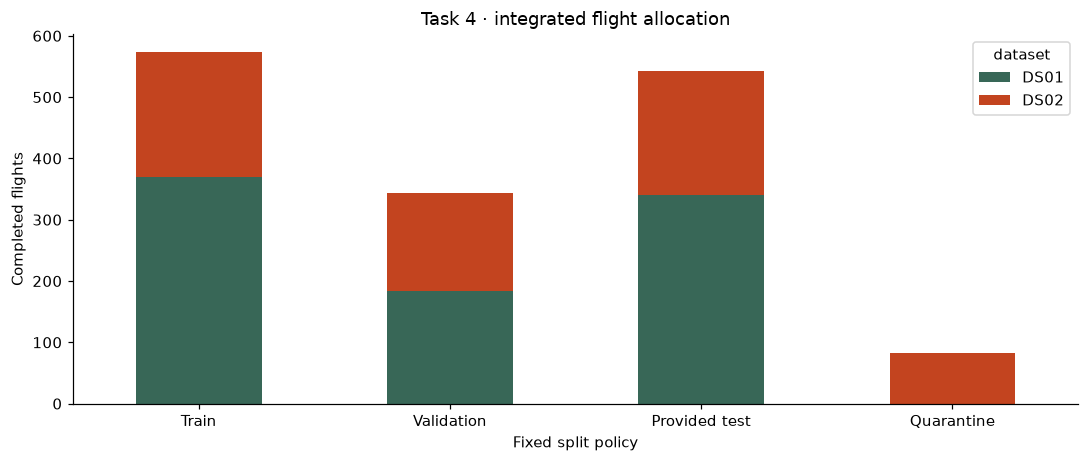

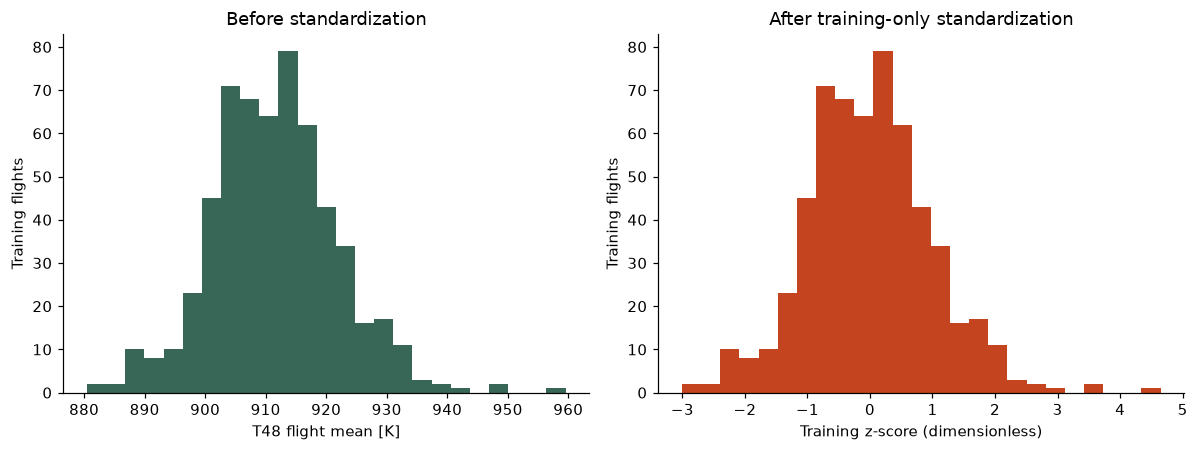

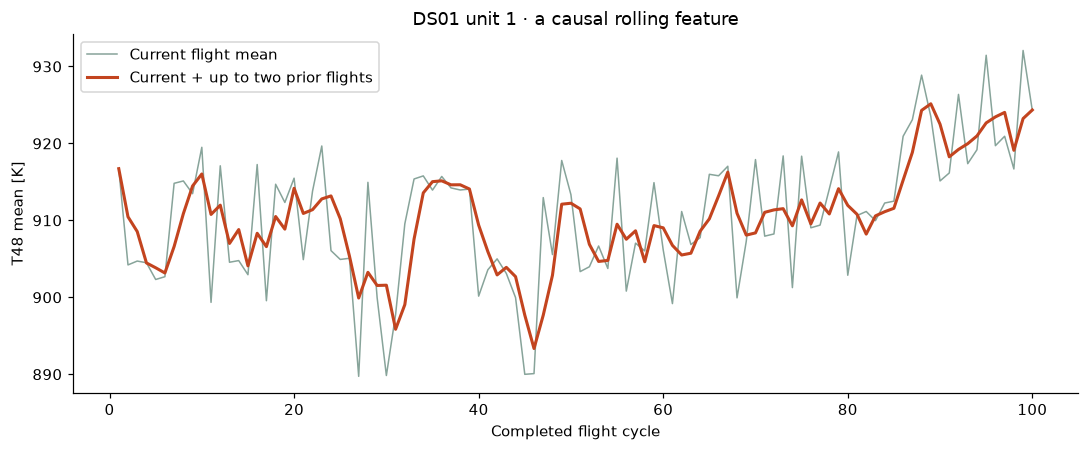

In [8]:
FIGURES=ROOT/'reports/figures'
def save(fig,name):
    fig.tight_layout()
    fig.savefig(FIGURES/f'{name}.svg',bbox_inches='tight',metadata={'Date':None})
    plt.show();plt.close(fig)
fig,ax=plt.subplots(figsize=(10,4.3))
counts=features.groupby(['split','dataset']).size().unstack(fill_value=0).reindex(['train','validation','test','quarantine_test_related'])
counts.plot.bar(stacked=True,ax=ax,color=['#386757','#c3441f'])
ax.set(xlabel='Fixed split policy',ylabel='Completed flights',title='Task 4 · integrated flight allocation')
ax.tick_params(axis='x',rotation=0)
ax.set_xticklabels(['Train','Validation','Provided test','Quarantine'])
save(fig,'task4_split_allocation')

fig,axes=plt.subplots(1,2,figsize=(11,4.2))
train=features[features.split=='train']
axes[0].hist(train.T48_K_mean,bins=25,color='#386757')
axes[0].set(title='Before standardization',xlabel='T48 flight mean [K]',ylabel='Training flights')
axes[1].hist(X_train['numeric__T48_K_mean'],bins=25,color='#c3441f')
axes[1].set(title='After training-only standardization',xlabel='Training z-score (dimensionless)',ylabel='Training flights')
save(fig,'task4_scaling')

fig,ax=plt.subplots(figsize=(10,4.2))
history=features[(features.dataset=='DS01')&(features.unit==1)]
ax.plot(history.cycle,history.T48_K_mean,label='Current flight mean',alpha=.6,linewidth=1)
ax.plot(history.cycle,history.T48_K_trailing3,label='Current + up to two prior flights',linewidth=2)
ax.set(title='DS01 unit 1 · a causal rolling feature',xlabel='Completed flight cycle',ylabel='T48 mean [K]')
ax.legend();save(fig,'task4_causal_history')

## 9 · What is versioned, and where is the cleaned dataset?
The output directory contains:
| Artifact | Purpose |
|---|---|
| `flights_features.csv` | All flight rows, physical-unit features, metadata, original RUL, and split |
| `X_train.csv`, `X_validation.csv`, `X_test.csv` | Fully numeric, finite feature matrices |
| `y_*.csv` | Corresponding true RUL labels, unchanged in flight cycles |
| `rows_*.csv` | Matching row identity/group metadata; same row order as X and y |
| `quarantine.csv` | Retained DS02 development unit 10 flights, excluded from modeling |
| `preprocessor.joblib` | Saved fitted imputer/scaler/encoder; not a prediction model |
| `baseline_columns.json` | The simpler 20-column input selection |
| `feature_catalog.csv`, audit/parameter CSVs | Feature definitions and fitted training parameters |
| `manifest.json` | Raw hashes, configuration, code hashes, environment, artifact checksums |

Raw HDF5 files stay in `data/raw/`; prepared versions stay in `data/processed/`. Both are local and ignored. Compact evidence under `reports/results/task4/` is suitable for review. The version fingerprint uses raw identity, policy, code and relevant package/Python versions. Existing matching artifacts are verified and reused rather than silently overwritten. Original raw files are never rewritten or copied into Git.

In [9]:
display(pd.DataFrame(manifest['raw_files']))
display(pd.DataFrame(manifest['artifacts']))
print('Complete local modeling dataset:',version_dir)
print('Version checksum verification:',verify_version(version_dir)['version_id'])
print('Preparation only: no RUL model has been fitted.')

,file,bytes,sha256
0,N-CMAPSS_DS01-005.h5,2873351432,3abdcee2a3c8136e8880e5d43ac8cdf12ab9f7f3ab3714...
1,N-CMAPSS_DS02-006.h5,2450472504,47971a68b239ecb756833218a95d68ded6eb7e63ee84e8...


,file,bytes,sha256
0,X_test.csv,398517,099897dbbf09d4d20da0854c2fef3516d83d084060fd27...
1,X_train.csv,420749,e7cf3a0b7753293103f9f5bbd4bbdcdf3c35990a760c31...
2,X_validation.csv,253706,eb7d048b9dd1ea65b02ac884b2360edea5dc2b9ecfc041...
3,baseline_columns.json,522,6e5499153fee805a98a32951a7b72956b26e970a3d9268...
4,cleaning_audit.csv,224,6fbca6cdc2e22860248061980538783210d64ddc3c1a38...
5,engine_splits.csv,767,fd1883d7ae7a23b01833b4e84ff6d5a7146c1c4acc7741...
6,feature_catalog.csv,6744,63c5c215993328710b0aa5771b72b2e004fe20acdcd88a...
7,flights_features.csv,1026901,3b6b444e86864647dd5e266489b5913909ce68ed7e8b3e...
8,imputation_parameters.csv,1662,b9a032fc206c490ca47721d6595cad233cc3ec188d5618...
9,preprocessor.joblib,6766,a97536d737bfdc5586659f1e31225c7a32d466a6582e1a...


Complete local modeling dataset: /home/selat/Projects/GR05-Predictive-Maintenance/data/processed/task4-v1-97719f3fe055
Version checksum verification: task4-v1-97719f3fe055
Preparation only: no RUL model has been fitted.


## 10 · Explain it to someone new to analytics
| Question | Plain-language answer |
|---|---|
| What did Task 4 change? | Turned many snapshots per flight into one consistent row, then split and transformed rows reproducibly |
| What is X? | The information a future model is allowed to see |
| What is y? | The historical answer, RUL, stored separately |
| Why use flight means and spread? | Means summarize typical behavior; spread captures within-flight variation |
| Is a mean enough to understand wear? | No; mission phases are mixed and context matters; this is a manageable first representation |
| Are rolling features using future data? | No: the current and previous completed flights only, within the same history |
| Why not put engine IDs into X? | IDs are bookkeeping labels and may encourage memorization |
| Why are first-flight differences missing? | There is no previous observed flight; this is expected, not a broken sensor |
| Why not delete every outlier? | Rare operating regimes can be valid and important |
| Why fit scaling on training only? | Otherwise held-out data would influence the preparation rules |
| Why is unit 10 quarantined in DS02? | Its shared ID appears in DS01 test and independence is unresolved |
| Are all 19 histories independent? | Not established; shared IDs are conservatively linked, other hidden dependencies remain possible |
| Is 50 columns too much? | We also supply a 20-column baseline; choose features using development validation later |
| Is this deployed aircraft maintenance software? | No: offline simulated-data research, with no operational certification or measured savings |

**Limitations:** only a few conservative engine groups; source shifts; whole-flight phase mixing; source version/terms still unverified; previous Task 3 test-label exposure is documented. The conservative grouping reduces one known risk, not a proof of independence. Source one-hot features can also learn collection effects; compare simpler DS01-only experiments later.

**Next:** fit a transparent baseline and a simple regressor on the prepared training data, evaluate development validation before final test, and report engine-wise MAE/RMSE. If cross-validating, refit preprocessing on each training fold rather than reusing statistics fitted on all 574 training rows.

### Sources and disclosure
- Supplied `tasks/IBS6 Industrial Analytics Project Tasks V4.0.pdf`, p. 2, dated 26 October 2026 (internal heading V12.0).
- [Task 3 report](../docs/05-data-understanding.md), actual HDF5 files, supplied Dataset Scales slides and feature-table example.
- [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html): fit transformations only on training data, use pipelines to avoid leakage.
- Official [SimpleImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.SimpleImputer.html), [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html), and [OneHotEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.OneHotEncoder.html) documentation.
- AI assistance and human review: [AI use log](../docs/ai-use-log.md).

After running this notebook, run `python scripts/build_task4_report.py` to regenerate the report and preparation webpage from evidence. Review interpretation with both team members before presentation.